# Federal student loan debt collection complaints
**Drew Thomasson · DSCI 3780 · Group 7**

Which issues appeared most often in published federal student loan debt collection complaints? How did the recorded company responses differ by issue?

Each row represents one published complaint in the group's snapshot of the CFPB Consumer Complaint Database. The scope here is **Debt collection → Federal student loan debt**. It covers that specific sub-product rather than all complaints about student loans. The shared file has 15 columns. We use complaint ID as a record key, UTC dates for coverage and routing checks, and the issue, sub-issue, submission channel, company and response fields as categories.

Open this notebook from the repository, select a Python kernel with pandas and Matplotlib installed, and run all cells. The notebook reads the shared CSVs from `Project/`. The original download date was not recorded in the repository.

[CFPB Consumer Complaint Database](https://www.consumerfinance.gov/data-research/consumer-complaints/) · [CFPB field definitions](https://www.consumerfinance.gov/complaint/data-use/) · [Course project example 4](../Project/Project_Examples_Fall_2026.pdf)

## Dataset columns

These are the **15 columns in the original CSV**, in file order. The two response fields and the timeliness flag describe different things. **Calendar days to send** is calculated later from the two date columns.

| CSV column | What it means |
| --- | --- |
| Date received | When the CFPB received the complaint. |
| Product | Broad CFPB category. Every row here is Debt collection. |
| Sub-product | Specific type of debt. Every row here is Federal student loan debt. |
| Issue | Main problem identified by the consumer. |
| Sub-issue | More specific problem identified by the consumer. |
| Company public response | Optional public-facing response category selected by the company. |
| Company | Company name or label recorded for the complaint. |
| State | State from the consumer’s mailing address, when available. |
| ZIP code | ZIP code from the consumer’s mailing address, when available. Read as text. |
| Tags | CFPB tags such as Servicemember or Older American, when available. |
| Submitted via | How the complaint was submitted, such as web, phone or postal mail. |
| Date sent to company | When the CFPB forwarded the complaint to the company. |
| Company response to consumer | Recorded response category, such as Closed with explanation. |
| Timely response? | CFPB’s Yes/No flag for whether the company responded on time. |
| Complaint ID | Unique complaint identifier. Read as text and checked for duplicates. |

[CFPB field definitions](https://www.consumerfinance.gov/complaint/data-use/)

## 1. Use the shared file and clean it in place in memory

Use `Project/federal_student_loan_debt.csv` as the group input. Munim's copy has the same 730 complaint IDs, plus 730 empty records and 45 ZIP codes that differ because leading zeros were lost. Read as text first so ZIP codes and complaint IDs keep their original formatting.

Trim surrounding whitespace and treat blank cells and the export's literal `None` as missing. Remove entirely blank rows and exact duplicate records. Check for missing IDs or conflicting records with the same ID before counting complaints, because choosing one version could change the results. Parse the two date fields as UTC timestamps so they can be ordered and compared.

In [1]:
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

project = next(
    (root / "Project" for root in [Path.cwd(), *Path.cwd().parents]
     if (root / "Project" / "federal_student_loan_debt.csv").is_file()),
    None,
)
if project is None:
    raise FileNotFoundError("Open the notebook from within the cloned group repository.")

id_col = "Complaint ID"
received = "Date received"
sent = "Date sent to company"
response = "Company response to consumer"
timely = "Timely response?"

def load_complaints(path):
    raw = pd.read_csv(path, dtype="string", keep_default_na=False)
    stripped = raw.apply(lambda column: column.str.strip())
    normalized = stripped.replace({"": pd.NA, "None": pd.NA})
    nonblank = normalized.dropna(how="all")
    clean = nonblank.drop_duplicates().copy()

    if clean[id_col].isna().any() or clean[id_col].duplicated().any():
        raise ValueError(f"Review missing or conflicting complaint IDs in {path.name}.")

    audit = {
        "Input rows": len(raw),
        "Input columns": len(raw.columns),
        "Cells trimmed": int(raw.ne(stripped).sum().sum()),
        "Blank rows removed": len(raw) - len(nonblank),
        "Exact duplicate rows removed": len(nonblank) - len(clean),
        "Unique complaints retained": len(clean),
    }
    for column in [received, sent]:
        original = clean[column]
        clean[column] = pd.to_datetime(original, utc=True, errors="coerce")
        audit[f"Unparseable values in {column}"] = int(
            (original.notna() & clean[column].isna()).sum()
        )
    return clean, audit

student, audit = load_complaints(project / "federal_student_loan_debt.csv")
assert student["Product"].eq("Debt collection").fillna(False).all()
assert student["Sub-product"].eq("Federal student loan debt").fillna(False).all()
display(pd.Series(audit, name="Count").to_frame())

,Count
Input rows,730
Input columns,15
Cells trimmed,0
Blank rows removed,0
Exact duplicate rows removed,0
Unique complaints retained,730
Unparseable values in Date received,0
Unparseable values in Date sent to company,0


## 2. Check missing values, categories and unusual dates

Keep complaints with missing optional fields. The public response is an optional field and has a different meaning from the response to the consumer. Check for category labels that would split across capitalization or spacing variants. Keep the original labels and rare response outcomes.

Calculate **calendar days to send** by subtracting the UTC date received from the UTC date sent to the company. This describes CFPB routing time. Company timeliness comes from the separate `Timely response?` flag.

In [2]:
missing = student.isna().sum().loc[lambda counts: counts.gt(0)]
display(missing.to_frame("Missing complaints").sort_values("Missing complaints", ascending=False))

category_columns = ["Issue", "Sub-issue", "Submitted via", response, timely]
category_checks = {}
for column in category_columns:
    labels = student[column].dropna().drop_duplicates()
    folded = labels.str.replace(r"\s+", " ", regex=True).str.casefold()
    category_checks[column] = {
        "Distinct labels": len(labels),
        "Labels sharing a normalized spelling": int(folded.duplicated(keep=False).sum()),
    }
display(pd.DataFrame.from_dict(category_checks, orient="index"))

student["Calendar days to send"] = (
    student[sent].dt.normalize() - student[received].dt.normalize()
).dt.days
routing = student["Calendar days to send"]
print(f"Received from {student[received].min():%Y-%m-%d} through {student[received].max():%Y-%m-%d} (UTC)")
print(f"Sent before received: {student[sent].lt(student[received]).sum()}")
print(f"Same UTC date: {routing.eq(0).sum()} of {routing.notna().sum()}")
print(f"Median: {routing.median():.0f} days | Mean: {routing.mean():.1f} days | Max: {routing.max():.0f} days")

,Missing complaints
Tags,660
Company public response,621
State,4
ZIP code,2


,Distinct labels,Labels sharing a normalized spelling
Issue,7,0
Sub-issue,25,0
Submitted via,4,0
Company response to consumer,5,0
Timely response?,2,0


Received from 2025-10-27 through 2026-10-23 (UTC)
Sent before received: 0
Same UTC date: 590 of 730
Median: 0 days | Mean: 4.4 days | Max: 83 days


All 730 complaints remain after cleaning. The missing values occur in public response, tags, state and ZIP code. All complaints have an issue and a recorded consumer response category. Routing was typically same-day (590 of 730), with a median of zero days and a maximum of 83. There were no records sent before the received timestamp, so the long delays stay in the dataset.

The observed dates span October 27, 2025 through October 23, 2026, across two calendar years. The first and last months are partial in the file. The full-snapshot charts use all 730 complaints.

## 3. Which issues were most common?

Each bar counts complaints assigned to one CFPB issue. The percent uses all 730 complaints as the denominator.

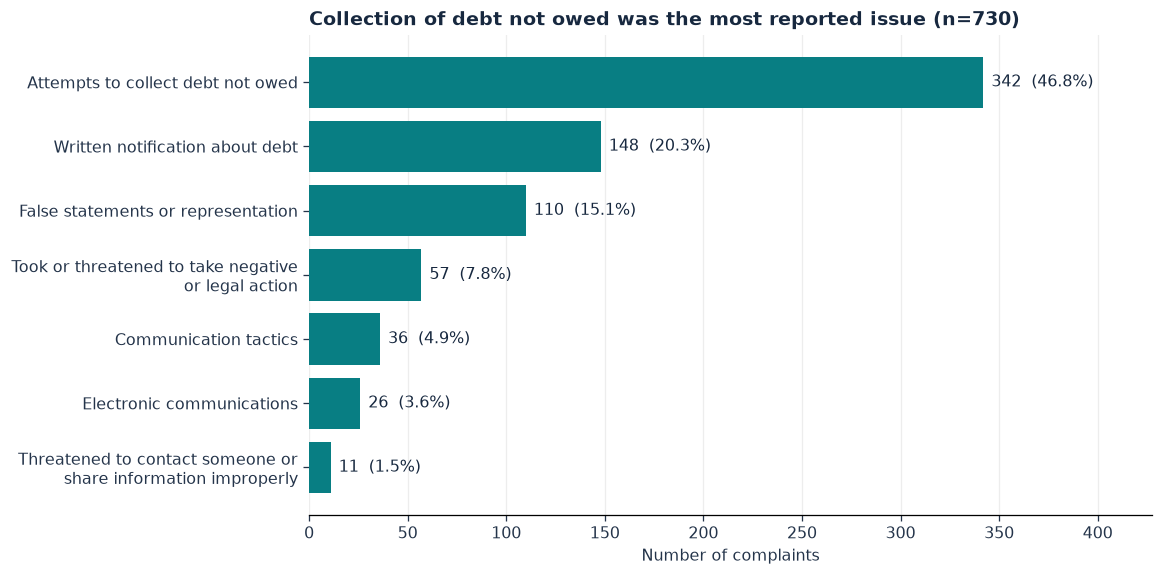

In [3]:
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#24344A",
    "text.color": "#17283F",
    "xtick.color": "#24344A",
    "ytick.color": "#24344A",
    "axes.axisbelow": True,
})

issue_counts = student["Issue"].value_counts()
n_student = len(student)
fig, ax = plt.subplots(figsize=(10, 4.9), layout="constrained")
bars = ax.barh([fill(label, 37) for label in issue_counts.index], issue_counts, color="#087E83")
ax.invert_yaxis()
ax.bar_label(
    bars, [f"{n}  ({n / n_student:.1%})" for n in issue_counts], padding=5
)
ax.set(xlim=(0, issue_counts.max() * 1.25), xlabel="Number of complaints")
ax.set_title(f"Collection of debt not owed was the most reported issue (n={n_student})", loc="left")
ax.grid(axis="x", alpha=0.22)
plt.show()

**Attempts to collect debt not owed** was the most common issue. It appeared in 342 of 730 complaints (46.8%), more than twice the next issue, written notification about debt (148). The 46.8% measures how often consumers raised this issue in the published complaints. Whether the debt was actually owed remains unverified in this dataset.

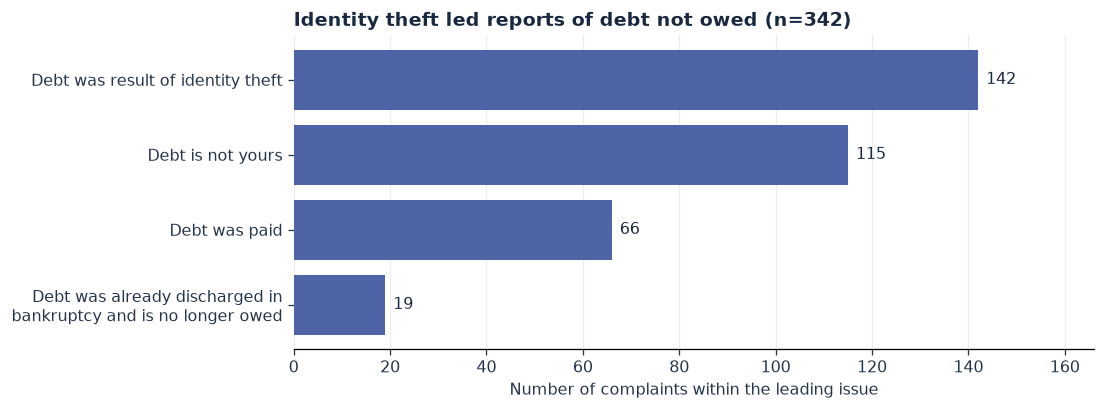

In [4]:
top_issue = issue_counts.index[0]
subissues = student.loc[student["Issue"].eq(top_issue), "Sub-issue"].value_counts()
fig, ax = plt.subplots(figsize=(9.5, 3.45), layout="constrained")
bars = ax.barh([fill(label, 37) for label in subissues.index], subissues, color="#4F64A6")
ax.invert_yaxis()
ax.bar_label(bars, padding=5)
ax.set(xlim=(0, subissues.max() * 1.17), xlabel="Number of complaints within the leading issue")
ax.set_title(f"Identity theft led reports of debt not owed (n={issue_counts.iloc[0]})", loc="left")
ax.grid(axis="x", alpha=0.22)
plt.show()

Within that issue, **142 of 342 complaints (41.5%)** said the debt resulted from identity theft, and **115 of 342 (33.6%)** selected “Debt is not yours”. These are complaint descriptions provided by consumers.

## 4. How did recorded responses differ by issue?

The chart divides each response count by all complaints in that issue. It keeps **In progress** in the denominator and shows all five recorded categories. Raw counts sit below the chart so small groups stay visible.

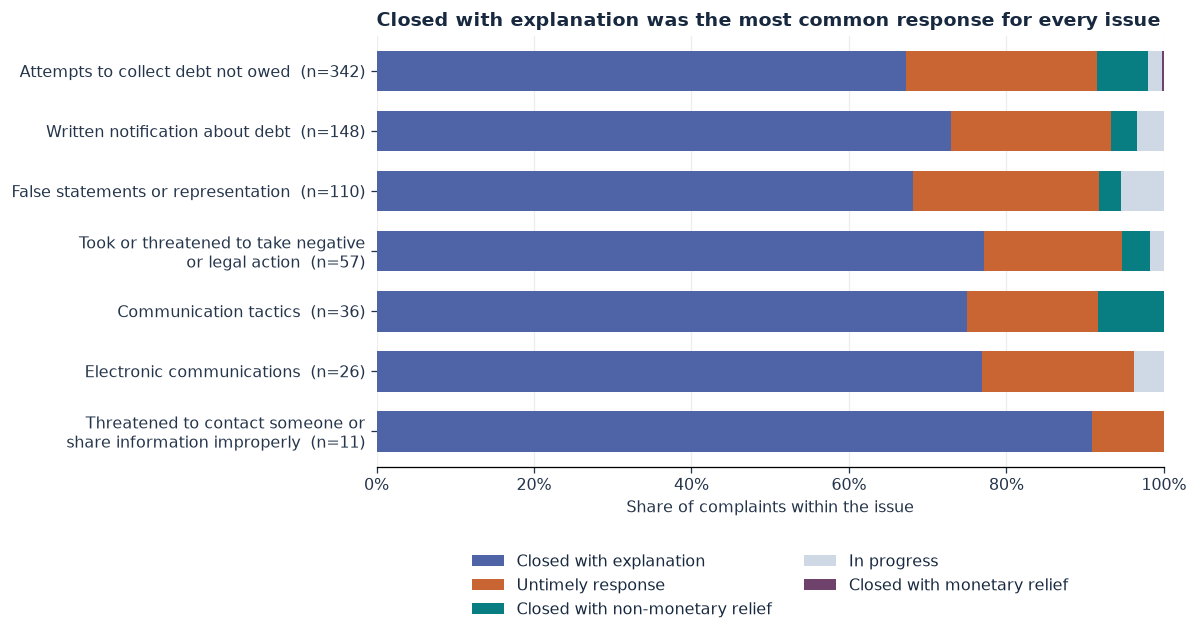

Company response to consumer,Closed with explanation,Untimely response,Closed with non-monetary relief,In progress,Closed with monetary relief,Total
Issue,,,,,,
Attempts to collect debt not owed,230,83,22,6,1,342
Written notification about debt,108,30,5,5,0,148
False statements or representation,75,26,3,6,0,110
Took or threatened to take negative or legal action,44,10,2,1,0,57
Communication tactics,27,6,3,0,0,36
Electronic communications,20,5,0,1,0,26
Threatened to contact someone or share information improperly,10,1,0,0,0,11


In [5]:
response_order = [
    "Closed with explanation",
    "Untimely response",
    "Closed with non-monetary relief",
    "In progress",
    "Closed with monetary relief",
]
colors = ["#4F64A6", "#C96532", "#087E83", "#CFD9E6", "#6E426B"]
outcomes = pd.crosstab(student["Issue"], student[response].fillna("Missing response"))
outcomes = outcomes.reindex(index=issue_counts.index)
extra_outcomes = outcomes.columns.difference(response_order).tolist()
outcomes = outcomes.reindex(columns=response_order + extra_outcomes, fill_value=0)
shares = outcomes.div(issue_counts, axis="index") * 100
plot_shares = shares.set_axis(
    [f"{fill(issue, 37)}  (n={issue_counts[issue]})" for issue in shares.index],
    axis="index",
)
ax = plot_shares.plot.barh(
    stacked=True, color=colors + ["#78828D"] * len(extra_outcomes),
    figsize=(10.3, 5.4), width=0.68,
)
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Share of complaints within the issue", ylabel="")
ax.xaxis.set_major_formatter(PercentFormatter())
ax.set_title("Closed with explanation was the most common response for every issue", loc="left")
ax.grid(axis="x", alpha=0.22)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
ax.figure.set_layout_engine("constrained")
plt.show()

display(outcomes.assign(Total=issue_counts))

- **Closed with explanation** accounted for 514 of 730 complaints (70.4%). **Untimely response** was the next most common category (161 of 730, 22.1%).
- The three most reported issues had similar shares labeled **Untimely response**. It was 83/342 (24.3%) for debt not owed, 30/148 (20.3%) for written notification and 26/110 (23.6%) for false statements. The smallest issue had only 11 complaints, so a single complaint changes its share by about 9 percentage points.
- **Monetary relief** appeared once in the snapshot. **In progress** appeared 19 times, and those statuses can change as complaints are resolved.

In [6]:
display(pd.crosstab(student[response], student[timely], margins=True))
display(student["Submitted via"].value_counts().to_frame("Complaints"))

untimely = student.loc[student[response].eq("Untimely response")]
company_counts = untimely["Company"].value_counts().head(2)
display(company_counts.to_frame("Untimely response complaints"))
print(f"Top two company labels accounted for {company_counts.sum()} of {len(untimely)} untimely outcomes.")

Timely response?,No,Yes,All
Company response to consumer,,,
Closed with explanation,10,504,514
Closed with monetary relief,0,1,1
Closed with non-monetary relief,0,35,35
In progress,0,19,19
Untimely response,161,0,161
All,171,559,730


,Complaints
Submitted via,
Web,707
Postal mail,10
Phone,7
Referral,6


,Untimely response complaints
Company,
Servicer under contract with Federal Student Aid,108
MOHELA,43


Top two company labels accounted for 151 of 161 untimely outcomes.


The two timeliness measures give different totals. The **Timely response?** flag is **No** for 171 complaints, including 10 recorded as **Closed with explanation**. Keep that flag distinct from the 161 outcomes labeled **Untimely response**.

A follow-up by company shows that **151 of 161** untimely outcomes (93.8%) were associated with two company labels in this snapshot. Company mix matters when interpreting the issue and debt-type comparisons. Web submissions made up **707 of 730** complaints, leaving only 23 across the other three channels, so there is little basis for comparing outcomes by channel here.

### What happened in the 342 complaints about debt the consumer said they didn’t owe?

| Recorded response category | Complaints | Share of these 342 complaints |
| --- | ---: | ---: |
| Closed with explanation | 230 | 67.3% |
| Untimely response | 83 | 24.3% |
| Closed with non-monetary relief | 22 | 6.4% |
| In progress | 6 | 1.8% |
| Closed with monetary relief | 1 | 0.3% |

**Closed with explanation** means the company reported giving a written explanation with no reported relief. **Closed with non-monetary relief** means the company reported taking a concrete action without a payment, such as correcting account information or stopping unwanted calls. Those are CFPB examples. The CSV has no details about which action was taken in the 22 cases. [CFPB response category definitions](https://files.consumerfinance.gov/f/documents/cfpb_2025-cr-annual-report_2026-03.pdf)

The company selects the response category. The category alone cannot establish whether the company agreed with the consumer, whether the debt was owed, or whether anyone knowingly gave false information. [CFPB guidance on how companies respond](https://www.consumerfinance.gov/compliance/consumer-complaint-program/company-process/)

### What the original source can add

- **Public complaint records.** Complaint ID identifies the complaint in the public CFPB data. The public fields exclude underlying account documents. [CFPB public fields](https://www.consumerfinance.gov/complaint/data-use/)
- **Public narratives archive.** Previously published consumer accounts through August 14, 2026 may add context for some earlier complaints. This analysis uses the structured repository export. The archive contains consumer accounts, and the CFPB says it does not verify the allegations in those accounts. [CFPB narratives archive](https://www.consumerfinance.gov/foia-requests/foia-electronic-reading-room/cfpb-consumer-complaint-database-narratives-archive/) · [CFPB statement on verification](https://www.consumerfinance.gov/about-us/newsroom/the-cfpb-to-cease-discretionary-publication-of-complaint-narratives-and-visualizations/)
- **Restricted case records.** Full company replies and attachments are available through a system that requires an approved data access agreement. No public file was identified that links our complaint IDs to loan records or case-by-case findings about who owed the debt. [CFPB Complaint Explorer](https://complaintexplorer.consumerfinance.gov/login/)

## 5. Does the team’s split make sense?

Dividing the work by debt type keeps the federal student loan patterns visible. For comparisons, use the same dates and definitions, and divide by the number of complaints within each debt type. A pooled figure would be dominated by credit card debt because its file is much larger.

The chart uses the shared full-month window **November 2025 through September 2026**, dropping the two October edge months for both groups. This is a comparison of the two repository exports over the same dates. Exact original filter settings and download dates are unavailable. An exploratory analysis can use the whole relevant snapshot. A train/test split would be relevant if the team later evaluates a predictive model.

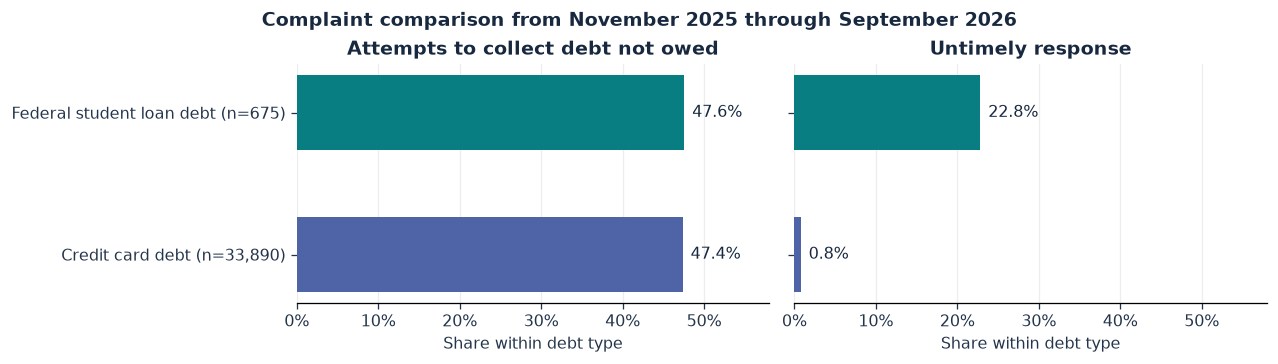

,Debt type,Metric,Count,Total,Share
0,Federal student loan debt,Attempts to collect debt not owed,321,675,47.6%
1,Federal student loan debt,Untimely response,154,675,22.8%
2,Credit card debt,Attempts to collect debt not owed,16051,33890,47.4%
3,Credit card debt,Untimely response,260,33890,0.8%


In [7]:
card, _ = load_complaints(project / "credit_card_debt.csv")
assert card["Product"].eq("Debt collection").fillna(False).all()
assert card["Sub-product"].eq("Credit card debt").fillna(False).all()

window_start = pd.Timestamp("2025-11-01", tz="UTC")
window_stop = pd.Timestamp("2026-10-01", tz="UTC")
comparison_rows = []
for label, frame in [("Federal student loan debt", student), ("Credit card debt", card)]:
    matched = frame.loc[frame[received].ge(window_start) & frame[received].lt(window_stop)]
    n = len(matched)
    for metric, count in [
        ("Attempts to collect debt not owed", matched["Issue"].eq("Attempts to collect debt not owed").sum()),
        ("Untimely response", matched[response].eq("Untimely response").sum()),
    ]:
        comparison_rows.append({
            "Debt type": label, "Metric": metric, "Count": count, "Total": n, "Share": count / n,
        })

comparison = pd.DataFrame(comparison_rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.05), sharey=True, layout="constrained")
for ax, (metric, group) in zip(axes, comparison.groupby("Metric", sort=False)):
    labels = [f"{label} (n={n:,})" for label, n in zip(group["Debt type"], group["Total"])]
    bars = ax.barh(labels, group["Share"], color=["#087E83", "#4F64A6"], height=0.53)
    ax.bar_label(bars, [f"{value:.1%}" for value in group["Share"]], padding=5)
    ax.set(xlim=(0, 0.58), xlabel="Share within debt type")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(metric)
    ax.grid(axis="x", alpha=0.22)
axes[0].invert_yaxis()
fig.suptitle("Complaint comparison from November 2025 through September 2026", fontweight="bold")
plt.show()

display(comparison.assign(Share=comparison["Share"].map("{:.1%}".format)))

In the matched months, about **48%** of complaints in each debt type were about collection of debt not owed (321/675 federal student loan complaints and 16,051/33,890 credit card complaints). The shares labeled **Untimely response** were **22.8%** and **0.8%**, respectively. This is a descriptive difference across the exports. Company mix, who files complaints, and publication and response timing can all affect what appears in the data.

## Takeaways for the presentation

1. **The leading issue was attempts to collect debt the consumer said they didn’t owe** (342 of 730 complaints, 46.8%). Reports of identity theft were the most common sub-issue within it.
2. **Most complaints were closed with an explanation.** The untimely outcome was concentrated under two company labels, and the three biggest issues had similar untimely shares.
3. **Keep the by-debt-type comparison.** The matched period shows that the top issue was nearly equally common while the recorded response mix differed. The CFPB database describes published complaints, so these percentages measure shares of complaints in the snapshot. Estimating customer-wide rates or comparing company performance would require exposure data and more context.